# Lane detection


In [13]:
import cv2
import numpy as np

from cv_utils import display, display_grid


In [14]:
import os
from pathlib import Path

from dotenv import load_dotenv
load_dotenv()

PROJECT_ROOT = Path(os.getenv("PROJECT_ROOT"))
DATA_DIR = Path(os.getenv("DATA_DIR"))

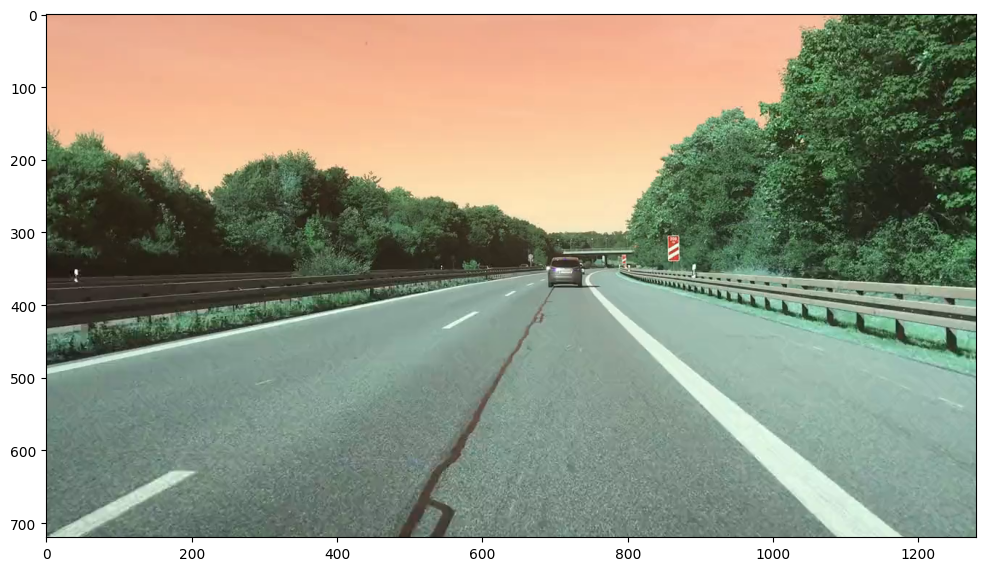

In [15]:
video_path = DATA_DIR / "assignments" / "DrivingVideo.mp4"

capture_img = cv2.VideoCapture(str(video_path))
capture_img = capture_img.read()[1]

display(capture_img)

In [16]:
from cv_utils.processing import EdgeDetector, ROIMask
from cv_utils.detection import LineDetector
from cv_utils.detection import LaneDetectionPipeline
from cv_utils.video import VideoProcessor
from cv_utils.shapes import Polygon
from cv_utils import ImageGeometry

In [17]:
def get_lanes_roi(img: np.ndarray) -> Polygon:
    """
    Get ROI polygon for lane detection.
    Coordinates are relative to input image (bottom_half).
    Uses ImageGeometry helpers for dynamic positioning.
    """
    height, width = img.shape[:2]

    # All coordinates relative to input image
    topcenter = ImageGeometry.get_top_center(img)
    topcenter_left_offset = (int(topcenter[0] - width / 30), 0)
    topcenter_right_offset = (int(topcenter[0] + width / 10), 0)

    topleft_down_offset = (0, int(height / 3.5))
    bottom_left = ImageGeometry.get_bottom_left(img)
    bottom_right = ImageGeometry.get_bottom_right(img)

    roi = Polygon(
        [
            topcenter_right_offset,
            bottom_right,
            bottom_left,
            topleft_down_offset,
            topcenter_left_offset,
        ]
    )
    return roi

ROI Mask: --- ROI Masking ---
Vertices: 5
ROI type: 5-corner polygon



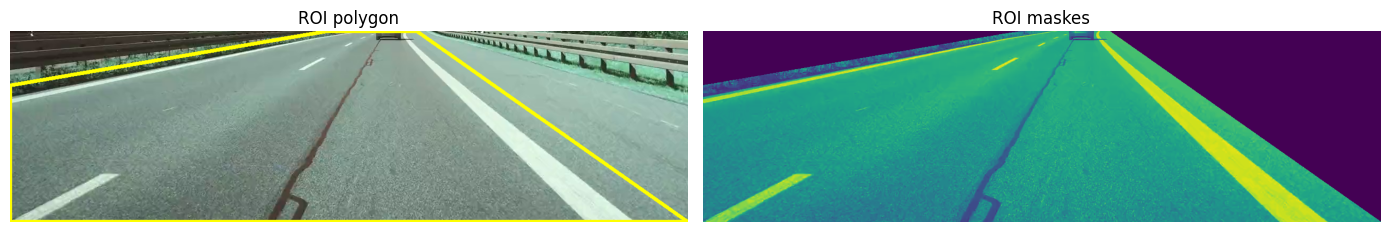

In [18]:
# Calculate ROI based on bottom_half dimensions
bottom_half = ImageGeometry.get_bottom_half(capture_img)
roi_poly = get_lanes_roi(bottom_half)
roi_mask = ROIMask(polygon=roi_poly)
print(f"ROI Mask: {roi_mask}")

# Visualize ROI polygon
bottom_half_viz = bottom_half.copy()
cv2.polylines(bottom_half_viz, [roi_poly.to_array()], True, (255, 255, 0), 5)

# Apply ROI mask
bottom_half_gray = cv2.cvtColor(bottom_half, cv2.COLOR_BGR2GRAY)
bottom_half_masked = roi_mask.apply(bottom_half_gray)

display_grid([bottom_half_viz, bottom_half_masked],
             titles=["ROI polygon", "ROI maskes"])

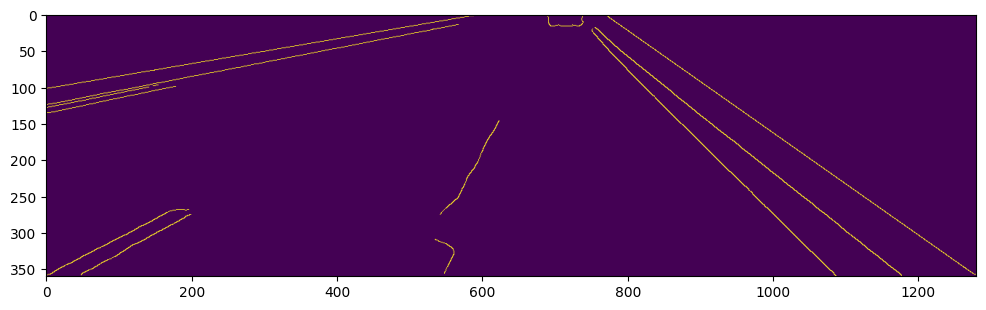

In [19]:
# Edge Detector
edge_detector = EdgeDetector(
    canny_low=150,
    canny_high=255,
    apply_smoothing=True,
    smoothing_method='median',
    smoothing_kernel=11
)
# Line Detector
line_detector = LineDetector(
    threshold=100,
    min_line_length=20,
    max_line_gap=500
)

bottom_half_edges = edge_detector.detect(bottom_half_masked)
display(bottom_half_edges)

In [20]:
# must use same scale for ROI and VideoProcessor!

SCALE = 1.0
roi_mask.scale(SCALE)

# 4. Combine into Lane Detection Pipeline
pipeline = LaneDetectionPipeline(
    roi_mask=roi_mask,
    edge_detector=edge_detector,
    line_detector=line_detector,
    drawing_params={'color': (0, 150, 255), 'thickness': 5},
    blend_params={'frame_weight': 0.7, 'line_weight': 0.5, 'gamma': 0.0}
)

In [21]:
# 5. Create Video Processor
video_processor = VideoProcessor(pipeline=pipeline,
                                video_source=video_path,
                                output_title=None,
                                scale=SCALE,
                                skip_frames=1  # Process every frame
)

print(video_processor)

VIDEO PROCESSOR

--- System ---
OS: Linux | Python: 3.10.8 | OpenCV: 4.8.0

--- Video Settings ---
Source: /home/dyretna/Dokument/Code/applied_ai_data/assignments/DrivingVideo.mp4
Format: 1280x720@60fps | Backend: FFMPEG
Scale: 1.0x | Skip: every 1 frame(s)

--- Pipeline ---

--- ROI Masking ---
Vertices: 5
ROI type: 5-corner polygon

--- Edge Detection (Canny) ---
Canny threshold low: 150
Canny threshold high: 255
Smoothing: median
Kernel size: 11

--- Line Detection (Hough Transform) ---
Rho: 1.0
Theta: 0.0175 rad
Threshold: 100
Min line length: 20
Max line gap: 500

--- Drawing Parameters ---
Line color (BGR): (0, 150, 255)
Line thickness: 5

--- Blending Parameters ---
Frame blend weight: 0.7
Line blend weight: 0.5
Gamma: 0.0



In [22]:
video_processor.process(show_display=True)

Detection in frame #1, count: 10
Detection in frame #2, count: 9
Detection in frame #3, count: 9
Detection in frame #4, count: 9
Detection in frame #5, count: 8
Detection in frame #6, count: 8
Detection in frame #7, count: 11
Detection in frame #8, count: 8
Detection in frame #9, count: 8
Detection in frame #10, count: 9
Detection in frame #11, count: 7
Detection in frame #12, count: 9
Detection in frame #13, count: 8
Detection in frame #14, count: 7
Detection in frame #15, count: 7
Detection in frame #16, count: 9
Detection in frame #17, count: 8
Detection in frame #18, count: 9
Detection in frame #19, count: 9
Detection in frame #20, count: 10
Detection in frame #21, count: 9
Detection in frame #22, count: 11
Detection in frame #23, count: 11
Detection in frame #24, count: 11
Detection in frame #25, count: 11
Detection in frame #26, count: 9
Detection in frame #27, count: 11
Detection in frame #28, count: 11
Detection in frame #29, count: 13
Detection in frame #30, count: 13
Detectio